# 02 — Trying forecasting methods

Demand and Inventory Planner · Development experiments · 2026-10-24

**Question:** Can Prophet or a pooled lag-feature regressor forecast four weeks of recorded product sales better than simple historical rules?

We compare all 50 training-selected UK products at the same ten development origins. This notebook fits real models and saves paired predictions. It does not evaluate the final partition, calibrate cumulative intervals, simulate inventory policies or promote a model. Source quality was inspected across the full dataset in notebook 01; this is not a claim that final labels have never been seen.

**Setup:** select this project's `.venv/bin/python` as the notebook kernel. From the project root, run `python -m pip install -r requirements.txt` and `python scripts/audit.py` if processed files are absent. Run all cells in order. Prophet is required; a missing installation fails explicitly rather than silently removing the method. All experiments run locally.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import hashlib
import json
import logging
import platform
import subprocess
import time
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from prophet import Prophet
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'config.json').exists(), 'Run from project root or notebooks/'
CONFIG = json.loads((ROOT / 'config.json').read_text())
SEED = 20261021
HORIZON = CONFIG['horizon_weeks']
assert HORIZON == 4, 'This experiment is specified for four weeks'
DEV_START = pd.Timestamp(CONFIG['development_start'])
TEST_START = pd.Timestamp(CONFIG['test_start'])
AUDIT = json.loads((ROOT / 'docs/reports/data-audit.json').read_text())
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()
for name in ['data/processed/weekly-sales.csv', 'data/processed/forecast-origins.csv', 'data/processed/selected-products.csv']:
    assert sha256(ROOT / name) == AUDIT['generated_sha256'][name], f'Rerun audit: {name}'
assert sha256(ROOT / 'config.json') == AUDIT['lineage']['config_sha256']
panel = pd.read_csv(ROOT / 'data/processed/weekly-sales.csv', dtype={'StockCode': str}, parse_dates=['week'])
panel = panel.loc[panel.week.lt(TEST_START)].copy()
origins = pd.read_csv(ROOT / 'data/processed/forecast-origins.csv', parse_dates=['origin', 'history_through', 'target_end'])
origins = origins.loc[origins.split.eq('development')].copy()
products = pd.read_csv(ROOT / 'data/processed/selected-products.csv', dtype={'StockCode': str})
assert len(products) == 50 and len(origins) == 10
assert not panel.duplicated(['StockCode', 'week']).any()
assert panel.units.ge(0).all() and np.isfinite(panel.units).all()
assert panel.week.max() < TEST_START and (origins.target_end < TEST_START).all()
RUNTIME = {p: version(p) for p in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'prophet', 'cmdstanpy', 'holidays', 'stanio', 'threadpoolctl']}
print('Python:', platform.python_version())
display(pd.Series(RUNTIME, name='installed version').to_frame())
plt.rcParams.update({'figure.figsize': (11, 4), 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
from cmdstanpy.utils import get_logger
get_logger().setLevel(logging.WARNING)  # initialize first; suppress routine fit messages, retain warnings/errors

Python: 3.9.6


,installed version
numpy,2.0.2
pandas,2.3.3
matplotlib,3.9.4
scikit-learn,1.6.1
prophet,1.1.7
cmdstanpy,1.2.5
holidays,0.83
stanio,0.5.1
threadpoolctl,3.6.0


## 1. Define a fair forecasting task

Each Monday we use history ending the preceding Sunday and predict the next four complete weeks. Development uses walk-forward refitting, so an earlier development actual can enter a later fit once observed. There is no random train/test split.

| Method | Forecast rule |
|---|---|
| Last week | Repeat the most recent observed week at all horizons |
| Mean 4 weeks | Repeat the preceding four-week average |
| Seasonal naive | Sales 52 weeks before each target week; last-week fallback when unavailable |
| Prophet | A separate trend/seasonality model per product and origin |
| Lag boosting, 7 / 15 leaves | A pooled supervised model across all products and horizons |

The trees use origin-anchored lags, trailing means/zero fractions, SKU, horizon and future-known calendar features. Missing long lags use native missing-value handling. All methods use the same recorded-sales target. The configuration and pre-run amendment are in the [evaluation plan](../docs/evaluation-plan.md).

In [2]:
import sys
sys.path.insert(0, str(ROOT / 'scripts'))
from forecasting import FEATURES, make_design, baseline_predictions, fit_lag_model

design = make_design(panel)
initial_training = panel.loc[panel.week.lt(DEV_START)]
scales = initial_training.groupby('StockCode').units.apply(lambda x: x.diff().abs().mean()).rename('scale')
assert len(scales) == 50
print(f'{len(design):,} historical supervised rows; {int(scales.eq(0).sum())} products with zero MASE scale')
display(origins[['origin', 'history_through', 'target_end']])
display(design.loc[design.origin.eq(origins.origin.min()), ['StockCode', 'origin', 'target_week', 'horizon', 'lag_1', 'lag_52', 'actual']].head(8))

15,188 historical supervised rows; 0 products with zero MASE scale


,origin,history_through,target_end
0,2011-06-06,2011-06-05,2011-07-03
1,2011-06-13,2011-06-12,2011-07-10
2,2011-06-20,2011-06-19,2011-07-17
3,2011-06-27,2011-06-26,2011-07-24
4,2011-07-04,2011-07-03,2011-07-31
5,2011-07-11,2011-07-10,2011-08-07
6,2011-07-18,2011-07-17,2011-08-14
7,2011-07-25,2011-07-24,2011-08-21
8,2011-08-01,2011-07-31,2011-08-28
9,2011-08-08,2011-08-07,2011-09-04


,StockCode,origin,target_week,horizon,lag_1,lag_52,actual
260,15036,2011-06-06,2011-06-06,1,193.0,1094.0,1562.0
261,15036,2011-06-06,2011-06-13,2,193.0,1094.0,973.0
262,15036,2011-06-06,2011-06-20,3,193.0,1094.0,145.0
263,15036,2011-06-06,2011-06-27,4,193.0,1094.0,131.0
572,16014,2011-06-06,2011-06-06,1,0.0,1000.0,20.0
573,16014,2011-06-06,2011-06-13,2,0.0,1000.0,12.0
574,16014,2011-06-06,2011-06-20,3,0.0,1000.0,0.0
575,16014,2011-06-06,2011-06-27,4,0.0,1000.0,0.0


## 2. Check temporal leakage and metric arithmetic

These are executable regression checks, including synthetic checks. Changing every value from a forecast origin onward must not change that origin's features or any permitted earlier fitting row. Multi-step lag inputs remain anchored to the same origin. MASE uses each product's fixed initial-training mean absolute one-week difference; zero-scale products remain in MAE/WAPE but are excluded from MASE with explicit counts.

In [3]:
def metric_summary(frame):
    absolute = (frame.prediction - frame.actual).abs()
    scale = frame.StockCode.map(scales).replace(0, np.nan)
    cumulative = frame.groupby(['StockCode', 'origin'])[['prediction', 'actual']].sum()
    denominator = float(frame.actual.abs().sum())
    return {'MASE': float((absolute / scale).mean()), 'MAE_units': float(absolute.mean()),
            'WAPE': float(absolute.sum() / denominator) if denominator else np.nan,
            'bias_units': float((frame.prediction - frame.actual).mean()),
            'four_week_MAE_units': float((cumulative.prediction - cumulative.actual).abs().mean()),
            'target_rows': len(frame), 'product_origins': len(cumulative),
            'WAPE_actual_units_denominator': denominator,
            'MASE_excluded_rows': int(scale.isna().sum())}

cutoff = origins.origin.min()
toy = panel.loc[panel.StockCode.eq(products.StockCode.iloc[0])].copy()
changed = toy.copy()
changed.loc[changed.week.ge(cutoff), 'units'] += 1000000
original_design, changed_design = make_design(toy), make_design(changed)
pd.testing.assert_frame_equal(original_design.loc[original_design.origin.eq(cutoff), FEATURES], changed_design.loc[changed_design.origin.eq(cutoff), FEATURES])
allowed = original_design.target_week.lt(cutoff)
pd.testing.assert_frame_equal(original_design.loc[allowed], changed_design.loc[allowed])
assert (design.history_through < design.origin).all()
example = design.loc[design.StockCode.eq(products.StockCode.iloc[0]) & design.origin.eq(cutoff)]
assert example.lag_1.nunique() == 1 and example.lag_13.nunique() == 1
synthetic_history = pd.Series([2., 4., 6.], index=pd.date_range('2010-01-04', periods=3, freq='W-MON'))
future = pd.date_range('2010-01-25', periods=4, freq='W-MON')
checks, fallback = baseline_predictions(synthetic_history, future)
assert fallback.all() and np.array_equal(checks['seasonal_naive'], [6.] * 4)
assert np.array_equal(checks['mean_4_weeks'], [4.] * 4)
annual_history = pd.Series(np.arange(60, dtype=float), index=pd.date_range('2010-01-04', periods=60, freq='W-MON'))
annual_targets = pd.date_range(annual_history.index[-1] + pd.Timedelta(weeks=1), periods=4, freq='W-MON')
annual_result, annual_fallback = baseline_predictions(annual_history, annual_targets)
assert not annual_fallback.any() and np.array_equal(annual_result['seasonal_naive'], [8., 9., 10., 11.])
# Known-case metrics on a real SKU with synthetic labels/predictions.
check_sku = scales.index[0]
metric_check = pd.DataFrame({'StockCode': [check_sku] * 4, 'origin': [cutoff] * 4,
                             'actual': [2., 4., 2., 4.], 'prediction': [1., 5., 3., 3.]})
known = metric_summary(metric_check)
assert np.isclose(known['MAE_units'], 1.) and np.isclose(known['WAPE'], 1 / 3)
assert np.isclose(known['MASE'], 1 / scales.loc[check_sku]) and known['four_week_MAE_units'] == 0
print('PASS: origin-feature invariance, fitting-row invariance, multi-step anchoring, seasonal fallback, annual lookup and metric arithmetic')

PASS: origin-feature invariance, fitting-row invariance, multi-step anchoring, seasonal fallback, annual lookup and metric arithmetic


## 3. Walk forward through development

Prophet has daily and weekly seasonality disabled because each observation is already one weekly total. Annual seasonality uses Fourier order three and prior scale one only when historical dates span at least 365 days. This is an explicit, constrained alternative to automatic seasonality selection, with limited annual evidence. No holiday terms are inferred from dates of weekly totals. Native uncertainty sampling is disabled for this point-forecast experiment.

Both boosted-tree settings follow the original small grid: learning rate 0.05, 150 iterations, minimum leaf size 20, L2=1 and no early stopping. SKU categories come only from the current fitting data. Fits use targets already observed before the current origin, even for older horizon-4 examples.

Expect 500 Prophet fits and 20 pooled tree fits. Errors stop execution rather than silently changing the evaluation population. The progress output records each completed origin. [Prophet weekly-data guidance](https://facebook.github.io/prophet/docs/non-daily_data.html); [scikit-learn 1.6 regressor reference](https://scikit-learn.org/1.6/modules/generated/sklearn.ensemble.HistGradientBoostingRegressor.html).

In [4]:
predictions, fit_records = [], []
last_prophet_model = None
start_run = time.perf_counter()
for origin in origins.origin:
    origin_started = time.perf_counter()
    target_rows = design.loc[design.origin.eq(origin)].sort_values(['StockCode', 'horizon']).copy()
    assert len(target_rows) == len(products) * HORIZON and target_rows.actual.notna().all()
    assert target_rows.target_week.max() < TEST_START
    base_rows = target_rows[['StockCode', 'origin', 'horizon', 'target_week', 'actual']].copy()
    baseline_values = {name: [] for name in ['last_week', 'mean_4_weeks', 'seasonal_naive']}
    seasonal_fallback, prophet_values = [], []
    for sku, targets in target_rows.groupby('StockCode', sort=True):
        history = panel.loc[panel.StockCode.eq(sku) & panel.week.lt(origin)].set_index('week').units.sort_index()
        values, fallback = baseline_predictions(history, targets.target_week)
        for name in baseline_values:
            baseline_values[name].extend(values[name])
        seasonal_fallback.extend(fallback)
        fit_started = time.perf_counter()
        annual = (history.index.max() - history.index.min()).days >= 365
        model = Prophet(growth='linear', yearly_seasonality=False,
                        weekly_seasonality=False, daily_seasonality=False,
                        changepoint_prior_scale=0.05, seasonality_prior_scale=1.,
                        n_changepoints=min(10, len(history) // 8), uncertainty_samples=0)
        if annual:
            model.add_seasonality(name='annual', period=365.25, fourier_order=3, prior_scale=1.)
        model.fit(pd.DataFrame({'ds': history.index, 'y': history.to_numpy()}), seed=SEED)
        forecast = model.predict(pd.DataFrame({'ds': targets.target_week.to_numpy()}))
        prophet_values.extend(np.maximum(forecast.yhat.to_numpy(), 0))
        fit_records.append({'method': 'prophet', 'StockCode': sku, 'origin': origin,
                            'history_last_week': history.index.max(), 'history_weeks': len(history),
                            'annual_enabled': annual, 'fit_and_predict_seconds': time.perf_counter() - fit_started})
        if sku == products.StockCode.iloc[0]:
            last_prophet_model = model
    for name, values in {**baseline_values, 'prophet': prophet_values}.items():
        rows = base_rows.assign(method=name, prediction=values, seasonal_fallback=False)
        if name == 'seasonal_naive':
            rows['seasonal_fallback'] = seasonal_fallback
        predictions.append(rows)
    fitting = design.loc[design.target_week.lt(origin) & design.actual.notna()]
    assert fitting.origin.max() < origin and fitting.target_week.max() < origin
    for leaves in [7, 15]:
        fit_started = time.perf_counter()
        model, estimate = fit_lag_model(fitting, target_rows, leaves=leaves, seed=SEED)
        name = f'lag_boosting_{leaves}'
        predictions.append(base_rows.assign(method=name, prediction=estimate, seasonal_fallback=False))
        fit_records.append({'method': name, 'StockCode': '__pooled__', 'origin': origin,
                            'history_last_week': fitting.target_week.max(), 'history_weeks': np.nan,
                            'annual_enabled': False, 'fit_and_predict_seconds': time.perf_counter() - fit_started})
    print(f'{origin.date()}: 50 products × 4 horizons × 6 methods; {time.perf_counter() - origin_started:.1f}s', flush=True)

predictions = pd.concat(predictions, ignore_index=True)
fits = pd.DataFrame(fit_records)
KEY = ['StockCode', 'origin', 'horizon', 'target_week']
assert not predictions.duplicated(KEY + ['method']).any()
assert np.isfinite(predictions.prediction).all() and predictions.prediction.ge(0).all()
assert predictions.groupby('method').size().eq(2000).all()
assert predictions.groupby(KEY).method.nunique().eq(6).all()
assert (fits.history_last_week < fits.origin).all()
assert predictions.target_week.max() < TEST_START
print(f'Completed {len(predictions):,} paired target rows in {time.perf_counter() - start_run:.1f}s; final evaluation unrun.')

2011-06-06: 50 products × 4 horizons × 6 methods; 3.4s


2011-06-13: 50 products × 4 horizons × 6 methods; 3.3s


2011-06-20: 50 products × 4 horizons × 6 methods; 3.4s


2011-06-27: 50 products × 4 horizons × 6 methods; 3.4s


2011-07-04: 50 products × 4 horizons × 6 methods; 3.3s


...

2011-07-18: 50 products × 4 horizons × 6 methods; 3.4s


2011-07-25: 50 products × 4 horizons × 6 methods; 3.5s


2011-08-01: 50 products × 4 horizons × 6 methods; 3.6s


2011-08-08: 50 products × 4 horizons × 6 methods; 3.6s


Completed 12,000 paired target rows in 34.2s; final evaluation unrun.


## 4. Which methods work on this development period?

MASE gives every product-origin equal weight using fixed training scales; lower is better. MAE is in units. WAPE weights larger sales more heavily and its denominator counts forecast targets, including repeated calendar weeks at different origins. Four-week MAE compares sums, allowing errors within a forecast window to offset. Bias is predicted minus actual units.

These are development results after comparing candidates, not unbiased final performance. Interval coverage, quantile loss, inventory cost, paired uncertainty and full release gates are not measured here.

,MASE,MAE_units,WAPE,bias_units,four_week_MAE_units,target_rows,product_origins,WAPE_actual_units_denominator,MASE_excluded_rows,fit_and_predict_seconds,MASE_improvement_vs_seasonal_pct,MASE_improvement_vs_mean4_pct
method,,,,,,,,,,,,
lag_boosting_7,0.6622,193.4374,0.6754,22.6011,501.4347,2000.0,500.0,572826.0,0.0,1.4462,38.1687,0.3081
lag_boosting_15,0.6635,193.7467,0.6765,18.8991,492.7563,2000.0,500.0,572826.0,0.0,1.9642,38.0460,0.1102
mean_4_weeks,0.6643,192.2440,0.6712,-4.0680,542.6680,2000.0,500.0,572826.0,0.0,NaN,37.9776,0.0000
prophet,0.7296,209.2431,0.7306,34.5559,617.4841,2000.0,500.0,572826.0,0.0,30.3303,31.8788,-9.8332
last_week,0.7964,227.7720,0.7953,-8.1170,757.6960,2000.0,500.0,572826.0,0.0,NaN,25.6348,-19.9004
seasonal_naive,1.0710,292.0590,1.0197,95.3290,813.7080,2000.0,500.0,572826.0,0.0,NaN,0.0000,-61.2320


Seasonal-naive fallback target rows: 0
Prophet fits with annual component: 500 / 500


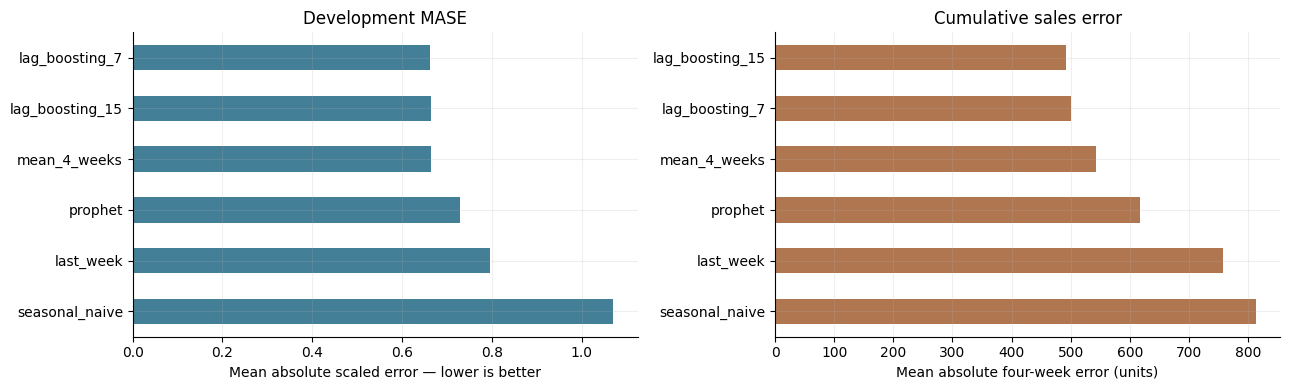

,MASE,MAE_units,WAPE,bias_units,four_week_MAE_units,target_rows,product_origins,WAPE_actual_units_denominator,MASE_excluded_rows
seasonal_fallback,,,,,,,,,
False,1.071,292.059,1.0197,95.329,813.708,2000.0,500.0,572826.0,0.0


In [5]:
metrics = pd.DataFrame({method: metric_summary(group) for method, group in predictions.groupby('method')}).T.sort_values('MASE')
metrics.index.name = 'method'
metrics['fit_and_predict_seconds'] = fits.groupby('method').fit_and_predict_seconds.sum().reindex(metrics.index)
metrics['MASE_improvement_vs_seasonal_pct'] = 100 * (1 - metrics.MASE / metrics.loc['seasonal_naive', 'MASE'])
metrics['MASE_improvement_vs_mean4_pct'] = 100 * (1 - metrics.MASE / metrics.loc['mean_4_weeks', 'MASE'])
display(metrics.round(4))
print('Seasonal-naive fallback target rows:', int(predictions.seasonal_fallback.sum()))
print('Prophet fits with annual component:', int(fits.loc[fits.method.eq('prophet'), 'annual_enabled'].sum()), '/', int(fits.method.eq('prophet').sum()))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
metrics.MASE.sort_values(ascending=False).plot.barh(ax=axes[0], color='#437f97')
axes[0].set(xlabel='Mean absolute scaled error — lower is better', ylabel='', title='Development MASE')
metrics.four_week_MAE_units.sort_values(ascending=False).plot.barh(ax=axes[1], color='#b07650')
axes[1].set(xlabel='Mean absolute four-week error (units)', ylabel='', title='Cumulative sales error')
fig.tight_layout()
plt.show()
fallback_metrics = pd.DataFrame({str(flag): metric_summary(g) for flag, g in predictions.loc[predictions.method.eq('seasonal_naive')].groupby('seasonal_fallback')}).T
fallback_metrics.index.name = 'seasonal_fallback'
display(fallback_metrics.round(4))

### What this first run tells us

The simple four-week mean is an essential comparator. The first run put its MASE at approximately 0.664, almost tied with the seven-leaf boosted model at 0.662; it also had slightly lower unit MAE. Prophet's MASE was approximately 0.730. Both the mean and learned models beat the annual seasonal-naive comparator on this period, but the learned model adds very little over the moving average.

Treat those numbers as the recorded first run, not expectations for every rerun after changing settings. A 0.3% development MASE difference does not establish a reliable advantage, especially with overlapping windows. The 15-leaf model has lower cumulative error than the seven-leaf model, showing that model rankings depend on the decision metric. Keep the moving average in subsequent comparisons and investigate product-level failures before adding complexity. No model has passed the full promotion gates.

## 5. Does a ranking hide unstable origins or weak products?

Inspect performance at each horizon and origin, then the largest product-level failures. Windows overlap and products share calendar shocks; the 2,000 rows per method are not 2,000 independent experiments. No confidence interval or savings claim follows from the mean ranking.

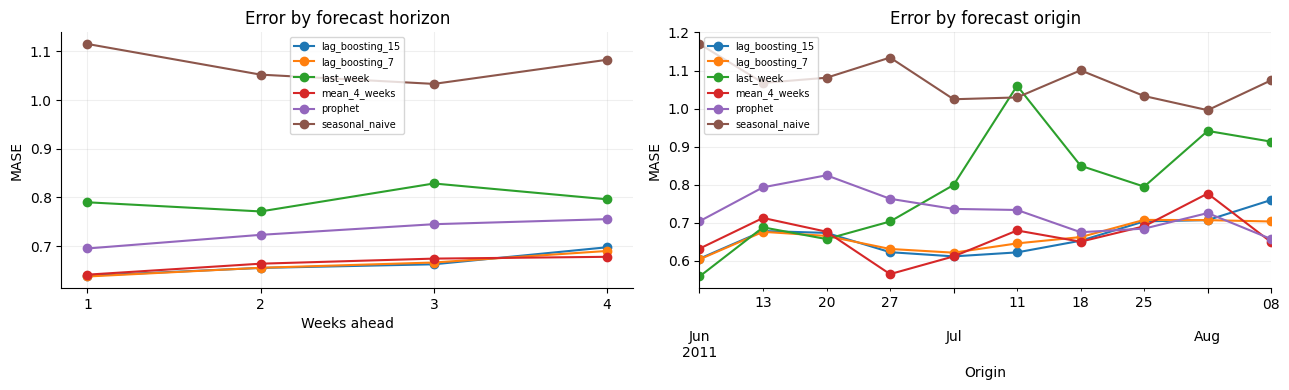

Lowest development MASE: lag_boosting_7 (exploratory ranking; not promoted)


,method,StockCode,MASE,MAE_units
88,lag_boosting_7,84568,1.601784,651.156561
72,lag_boosting_7,22151,1.501033,273.324474
82,lag_boosting_7,47566,1.475731,192.956564
91,lag_boosting_7,84879,1.187531,522.652436
71,lag_boosting_7,22086,1.027317,103.278669
95,lag_boosting_7,84992,0.996769,258.888094
50,lag_boosting_7,15036,0.964170,438.985321
92,lag_boosting_7,84946,0.943542,164.151758
81,lag_boosting_7,22616,0.926664,443.971581
65,lag_boosting_7,21977,0.923381,310.483877


,StockCode,origin,horizon,target_week,method,actual,prediction,absolute_error
11211,17003,2011-08-08,4,2011-08-29,seasonal_naive,291.0,11138.00000,10847.00000
9755,84568,2011-08-01,4,2011-08-22,last_week,0.0,4384.00000,4384.00000
9754,84568,2011-08-01,3,2011-08-15,last_week,0.0,4384.00000,4384.00000
6154,84568,2011-07-11,3,2011-07-25,last_week,4384.0,8.00000,4376.00000
8952,84568,2011-07-25,1,2011-07-25,seasonal_naive,4384.0,27.00000,4357.00000
7753,84568,2011-07-18,2,2011-07-25,seasonal_naive,4384.0,27.00000,4357.00000
6554,84568,2011-07-11,3,2011-07-25,seasonal_naive,4384.0,27.00000,4357.00000
5355,84568,2011-07-04,4,2011-07-25,seasonal_naive,4384.0,27.00000,4357.00000
9753,84568,2011-08-01,2,2011-08-08,last_week,35.0,4384.00000,4349.00000
8552,84568,2011-07-25,1,2011-07-25,last_week,4384.0,44.00000,4340.00000


In [6]:
scored = predictions.copy()
scored['absolute_error'] = (scored.prediction - scored.actual).abs()
scored['scaled_absolute_error'] = scored.absolute_error / scored.StockCode.map(scales).replace(0, np.nan)
horizon_metrics = scored.groupby(['method', 'horizon']).agg(MASE=('scaled_absolute_error', 'mean'), MAE_units=('absolute_error', 'mean')).reset_index()
origin_metrics = scored.groupby(['method', 'origin']).scaled_absolute_error.mean().unstack('method')
product_metrics = scored.groupby(['method', 'StockCode']).agg(MASE=('scaled_absolute_error', 'mean'), MAE_units=('absolute_error', 'mean')).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for method, group in horizon_metrics.groupby('method'):
    axes[0].plot(group.horizon, group.MASE, marker='o', label=method)
origin_metrics.plot(ax=axes[1], marker='o')
axes[0].set(title='Error by forecast horizon', xlabel='Weeks ahead', ylabel='MASE', xticks=[1, 2, 3, 4])
axes[1].set(title='Error by forecast origin', xlabel='Origin', ylabel='MASE')
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
fig.tight_layout()
plt.show()
best_method = metrics.index[0]
print('Lowest development MASE:', best_method, '(exploratory ranking; not promoted)')
display(product_metrics.loc[product_metrics.method.eq(best_method)].sort_values('MASE', ascending=False).head(10))
display(scored.sort_values('absolute_error', ascending=False)[KEY + ['method', 'actual', 'prediction', 'absolute_error']].head(12))

## 6. Inspect actual forecast paths

Use a single selected origin so overlapping predictions are not accidentally stitched into a fictitious time series. The examples use training-ranked products rather than selecting attractive forecast results. Change `PLOT_ORIGIN` to another development date to inspect a different historical decision.

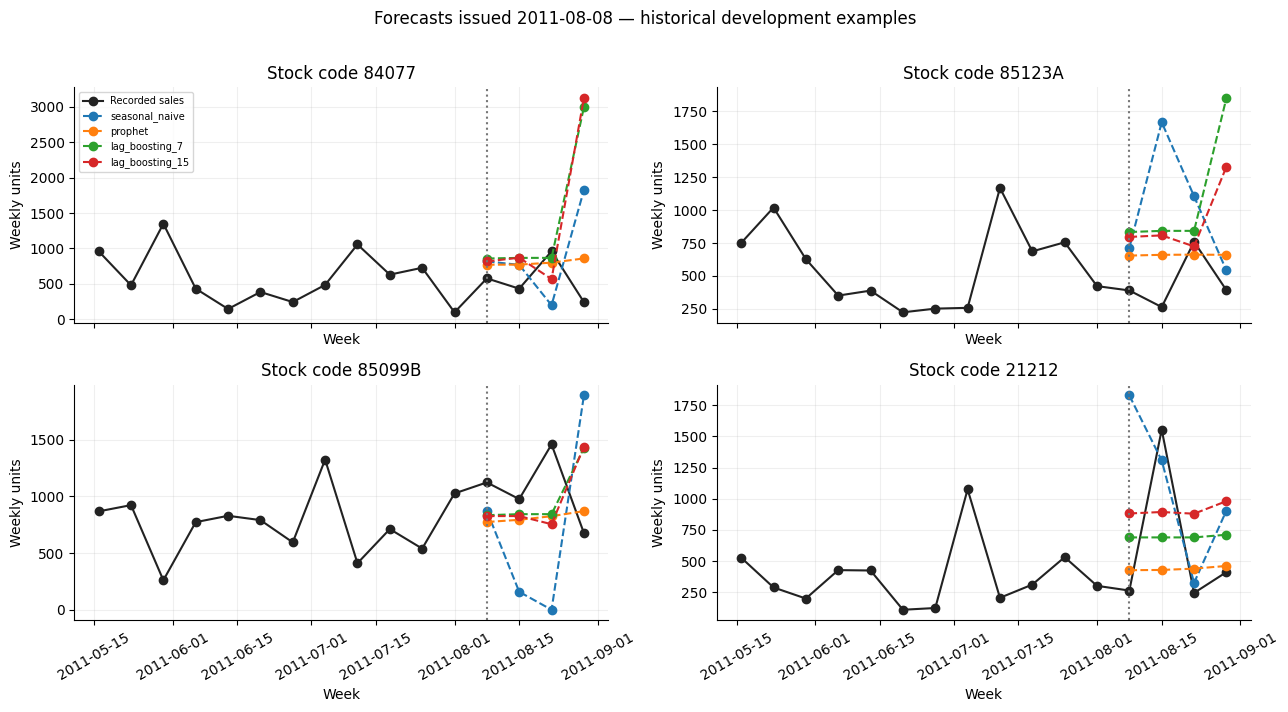

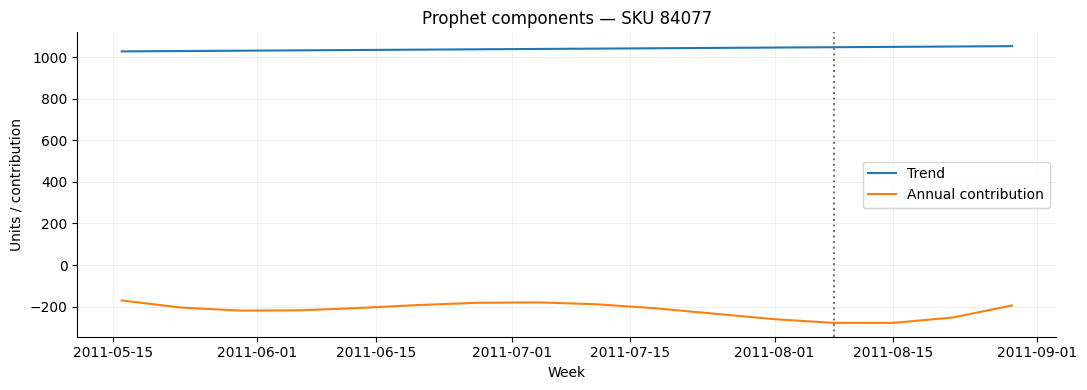

In [7]:
PLOT_ORIGIN = origins.origin.iloc[-1]
PLOT_METHODS = list(dict.fromkeys(['seasonal_naive', 'prophet', 'lag_boosting_7', 'lag_boosting_15']))
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for ax, sku in zip(axes.flat, products.StockCode.head(4)):
    history = panel.loc[panel.StockCode.eq(sku) & panel.week.ge(PLOT_ORIGIN - pd.Timedelta(weeks=12)) & panel.week.lt(PLOT_ORIGIN + pd.Timedelta(weeks=4))]
    ax.plot(history.week, history.units, color='#222222', marker='o', label='Recorded sales')
    view = predictions.loc[predictions.StockCode.eq(sku) & predictions.origin.eq(PLOT_ORIGIN)]
    for method in PLOT_METHODS:
        forecast = view.loc[view.method.eq(method)]
        ax.plot(forecast.target_week, forecast.prediction, marker='o', linestyle='--', label=method)
    ax.axvline(PLOT_ORIGIN, color='#777777', linestyle=':')
    ax.set(title=f'Stock code {sku}', ylabel='Weekly units', xlabel='Week')
    ax.tick_params(axis='x', rotation=30)
axes.flat[0].legend(fontsize=7)
fig.suptitle(f'Forecasts issued {PLOT_ORIGIN.date()} — historical development examples', y=1.01)
fig.tight_layout()
plt.show()
# Interpretability view of the final development fit for the leading training-volume product.
component_dates = pd.date_range(PLOT_ORIGIN - pd.Timedelta(weeks=12), periods=16, freq='W-MON')
components = last_prophet_model.predict(pd.DataFrame({'ds': component_dates}))
fig, ax = plt.subplots()
ax.plot(components.ds, components.trend, label='Trend')
if 'annual' in components:
    ax.plot(components.ds, components.annual, label='Annual contribution')
ax.axvline(PLOT_ORIGIN, color='#777777', linestyle=':')
ax.set(title=f'Prophet components — SKU {products.StockCode.iloc[0]}', ylabel='Units / contribution', xlabel='Week')
ax.legend()
fig.tight_layout()
plt.show()

## 7. Save reviewable results and lineage

Save predictions and diagnostics in `data/processed/` (regenerable, Git-ignored). Save compact summary tables and a machine-readable run report under `docs/reports/`. The notebook fingerprint covers source cells rather than changing execution outputs. No fitted model is registered or represented as production.

In [8]:
REPORTS = ROOT / 'docs/reports'
PROCESSED = ROOT / 'data/processed'
REPORTS.mkdir(parents=True, exist_ok=True)
outputs = {PROCESSED / 'development-forecast-predictions.csv': predictions,
           PROCESSED / 'development-forecast-fit-diagnostics.csv': fits,
           PROCESSED / 'development-forecast-product-metrics.csv': product_metrics,
           REPORTS / 'forecasting-development-metrics.csv': metrics.reset_index(),
           REPORTS / 'forecasting-development-horizon-metrics.csv': horizon_metrics,
           REPORTS / 'forecasting-development-origin-metrics.csv': origin_metrics.reset_index()}
for path, frame in outputs.items():
    frame.to_csv(path, index=False)
notebook_path = ROOT / 'notebooks/02-forecasting-methods.ipynb'
notebook_on_disk = json.loads(notebook_path.read_text())
source_text = json.dumps([{'cell_type': c['cell_type'], 'source': ''.join(c['source'])} for c in notebook_on_disk['cells']], sort_keys=True)
revision = subprocess.run(['git', 'rev-parse', 'HEAD'], cwd=ROOT, text=True, capture_output=True, check=True).stdout.strip()
report = {'experiment': 'development-point-forecasts-v1', 'date': '2026-10-24',
          'scope': '50 fixed products; ten development origins; four horizons; final forecast evaluation unrun',
          'git_revision': revision, 'git_worktree_dirty': bool(subprocess.run(['git', 'status', '--porcelain'], cwd=ROOT, text=True, capture_output=True, check=True).stdout.strip()),
          'notebook_source_sha256': hashlib.sha256(source_text.encode()).hexdigest(),
          'forecasting_code_sha256': sha256(ROOT / 'scripts/forecasting.py'),
          'reproduced_date': '2026-10-25',
          'config_sha256': sha256(ROOT / 'config.json'), 'config': CONFIG,
          'panel_sha256': sha256(ROOT / 'data/processed/weekly-sales.csv'),
          'origins_sha256': sha256(ROOT / 'data/processed/forecast-origins.csv'),
          'selected_products_sha256': sha256(ROOT / 'data/processed/selected-products.csv'),
          'source_csv_sha256': AUDIT['lineage']['sources'],
          'python': platform.python_version(), 'packages': RUNTIME, 'seed': SEED,
          'methods': metrics.index.tolist(), 'products': len(products), 'origins': len(origins),
          'target_rows_per_method': 2000, 'zero_scale_products': int(scales.eq(0).sum()),
          'seasonal_fallback_target_rows': int(predictions.seasonal_fallback.sum()),
          'prophet_annual_fits': int(fits.loc[fits.method.eq('prophet'), 'annual_enabled'].sum()),
          'metrics': json.loads(metrics.reset_index().to_json(orient='records')),
          'artifacts_sha256': {str(path.relative_to(ROOT)): sha256(path) for path in outputs},
          'checks': ['future-feature invariance', 'future fitting-row invariance', 'multi-step lag anchoring',
                     'seasonal fallback and annual lookup', 'known-case metric arithmetic',
                     'same forecast keys for every method', 'finite nonnegative predictions', 'all fits pre-origin', 'no final targets'],
          'limitations': ['Development selection, not final validation', 'Recorded sales, not unconstrained demand',
                         'Overlapping targets and shared calendar shocks', 'Point forecasts only; no calibrated intervals or policy costs',
                         'Limited annual history; no release promotion']}
(REPORTS / 'forecasting-development.json').write_text(json.dumps(report, indent=2, allow_nan=False) + '\n')
summary = f"""# Development forecasting experiments

Run 2026-10-24 via `notebooks/02-forecasting-methods.ipynb`. Compared six methods on 50 training-selected UK products, ten development origins and four horizons: 2,000 forecast targets per method. Origins overlap; no final-test forecast evaluation has run.

Lowest development MASE: **{best_method}**, {metrics.loc[best_method, 'MASE']:.4f}. Seasonal naive: {metrics.loc['seasonal_naive', 'MASE']:.4f}. Prophet: {metrics.loc['prophet', 'MASE']:.4f}. The four-week moving average has MASE {metrics.loc['mean_4_weeks', 'MASE']:.4f}; the best method improves on it by only {metrics.loc[best_method, 'MASE_improvement_vs_mean4_pct']:.2f}%. These are exploratory point-forecast results, not a production promotion or measured inventory savings. See the notebook's paired origin/horizon plots and product failures, plus `forecasting-development-metrics.csv` and `forecasting-development.json` for exact metrics and lineage.

Seasonal fallback targets: {int(predictions.seasonal_fallback.sum())}; annual-enabled Prophet fits: {report['prophet_annual_fits']} / 500. Missing 52-week lags use native tree handling. Forecasts are clipped nonnegative; customer identity, actual future prices and future-week sales are not inputs.

Passed executable leakage, fallback, arithmetic and comparison-population checks. Next: inspect instability and duplicate/extreme-order sensitivity, calibrate cumulative historical uncertainty, compare inventory scenarios, and freeze a candidate before final evaluation. Full promotion gates remain unassessed.
"""
(REPORTS / '02-forecasting-methods.md').write_text(summary)
print(summary)
print('Saved paired predictions, fit diagnostics, metrics and lineage.')

# Development forecasting experiments

Run 2026-10-24 via `notebooks/02-forecasting-methods.ipynb`. Compared six methods on 50 training-selected UK products, ten development origins and four horizons: 2,000 forecast targets per method. Origins overlap; no final-test forecast evaluation has run.

Lowest development MASE: **lag_boosting_7**, 0.6622. Seasonal naive: 1.0710. Prophet: 0.7296. The four-week moving average has MASE 0.6643; the best method improves on it by only 0.31%. These are exploratory point-forecast results, not a production promotion or measured inventory savings. See the notebook's paired origin/horizon plots and product failures, plus `forecasting-development-metrics.csv` and `forecasting-development.json` for exact metrics and lineage.

Seasonal fallback targets: 0; annual-enabled Prophet fits: 500 / 500. Missing 52-week lags use native tree handling. Forecasts are clipped nonnegative; customer identity, actual future prices and future-week sales are not inputs.

Pas

## Continue experimenting

Use the tables and product examples to decide what deserves a second experiment. A lower development average alone does not justify deployment. Before interpreting replenishment decisions, add completed-window cumulative calibration and evaluate quantile loss, coverage, scenario costs and robustness to duplicate removal and bulk orders. Any new settings should be documented before a rerun. Keep final evaluation separate until the recipe is frozen.